# 1. Import libraries

In [10]:
from pathlib import Path

import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

plt.style.use("ggplot")


# 2. Project directories

In [11]:
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "requirements.txt").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
IMAGES_DIR = PROJECT_DIR / "docs" / "images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Images directory:", IMAGES_DIR)


Project directory: c:\Users\Rafael\Documents\Projects\Personal\Data\b3-analytics
Data directory: c:\Users\Rafael\Documents\Projects\Personal\Data\b3-analytics\data
Images directory: c:\Users\Rafael\Documents\Projects\Personal\Data\b3-analytics\docs\images


# 3. Load PETR4 from Excel and obtain VALE3


In [12]:
multi_asset_file = DATA_DIR / "vale3_hist.xlsx"
petr4_file = DATA_DIR / "petr4_hist.xlsx"

if multi_asset_file.exists():
    # Preferred option: both assets are already in the Excel workbook.
    raw_prices = pd.read_excel(
        multi_asset_file,
        sheet_name="Prices",
        index_col=0,
        parse_dates=True,
        engine="calamine"
    )

    raw_prices.columns = raw_prices.columns.astype(str).str.strip()
    rename_map = {
        "PETR4.SA": "PETR4",
        "VALE3.SA": "VALE3",
    }
    raw_prices = raw_prices.rename(columns=rename_map)

    missing_assets = [
        asset for asset in ["PETR4", "VALE3"]
        if asset not in raw_prices.columns
    ]
    if missing_assets:
        raise ValueError(
            f"{multi_asset_file.name} is missing columns for {missing_assets}. "
            f"Available columns: {list(raw_prices.columns)}"
        )

    prices = raw_prices[["PETR4", "VALE3"]].copy()
    prices.index = pd.to_datetime(prices.index)
    if getattr(prices.index, "tz", None) is not None:
        prices.index = prices.index.tz_localize(None)

else:
    # Fallback: load PETR4 from the existing workbook and download VALE3.
    if not petr4_file.exists():
        raise FileNotFoundError(
            f"Could not find {multi_asset_file} or {petr4_file}. "
            "Run main.py first to create the Excel file."
        )

    petr4_data = pd.read_excel(
        petr4_file,
        index_col=0,
        parse_dates=True,
        engine="calamine"
    )

    petr4_data.columns = petr4_data.columns.astype(str).str.strip()
    if "Close" not in petr4_data.columns:
        raise ValueError(
            f"Expected a 'Close' column in {petr4_file.name}. "
            f"Available columns: {list(petr4_data.columns)}"
        )

    petr4_data.index = pd.to_datetime(petr4_data.index)
    if getattr(petr4_data.index, "tz", None) is not None:
        petr4_data.index = petr4_data.index.tz_localize(None)

    petr4_close = pd.to_numeric(petr4_data["Close"], errors="coerce").dropna()
    if petr4_close.empty:
        raise ValueError("No valid PETR4 closing prices were found in the Excel file.")

    start_date = petr4_close.index.min().date().isoformat()
    end_date = (petr4_close.index.max() + pd.Timedelta(days=1)).date().isoformat()

    print("Downloading VALE3.SA for the PETR4 date range...")
    vale3_data = yf.Ticker("VALE3.SA").history(
        start=start_date,
        end=end_date,
        interval="1d",
        auto_adjust=True
    )

    if vale3_data.empty or "Close" not in vale3_data.columns:
        raise RuntimeError(
            "No VALE3.SA data was returned. Check your internet connection "
            "and the ticker symbol."
        )

    vale3_data.index = pd.to_datetime(vale3_data.index)
    if getattr(vale3_data.index, "tz", None) is not None:
        vale3_data.index = vale3_data.index.tz_localize(None)

    vale3_close = pd.to_numeric(vale3_data["Close"], errors="coerce").dropna()

    prices = pd.concat(
        [
            petr4_close.rename("PETR4"),
            vale3_close.rename("VALE3"),
        ],
        axis=1
    )

# Ensure numeric values, sort dates, and use common dates for fair comparison.
prices = prices.apply(pd.to_numeric, errors="coerce").sort_index()
prices = prices.dropna(subset=["PETR4", "VALE3"], how="any")
prices = prices[~prices.index.duplicated(keep="last")]

if prices.empty:
    raise ValueError("No dates overlap between PETR4 and VALE3.")

display(prices.head())
display(prices.tail())
print(f"Observations on common dates: {len(prices)}")
print(f"Comparison period: {prices.index.min().date()} to {prices.index.max().date()}")


,PETR4,VALE3
Date,,
2025-10-29,27.362547,58.536957
2025-10-30,27.244053,58.980629
2025-10-31,27.116447,60.320889
2025-11-03,27.435465,60.404076
2025-11-04,27.572184,59.729328


,PETR4,VALE3
Date,,
2026-10-23,58.680000,61.900002
2026-10-26,53.880001,64.379997
2026-10-27,52.790001,63.000000
2026-10-28,52.509998,61.380001
2026-10-29,52.200001,60.049999


Observations on common dates: 249
Comparison period: 2025-10-29 to 2026-10-29


# 4. Calculate daily and cumulative returns

In [13]:
daily_returns = prices.pct_change(fill_method=None)
cumulative_returns = (1 + daily_returns.fillna(0)).cumprod() - 1

# Normalize both assets to 100 on the first common date.
normalized_prices = prices.div(prices.iloc[0]).mul(100)

display(daily_returns.tail())
display(cumulative_returns.tail())


,PETR4,VALE3
Date,,
2026-10-23,0.014698,0.006668
2026-10-26,-0.081800,0.040065
2026-10-27,-0.020230,-0.021435
2026-10-28,-0.005304,-0.025714
2026-10-29,-0.005904,-0.021668


,PETR4,VALE3
Date,,
2026-10-23,1.144537,0.057452
2026-10-26,0.969115,0.099818
2026-10-27,0.929280,0.076243
2026-10-28,0.919046,0.048568
2026-10-29,0.907717,0.025848


# 5. Comparative chart: Normalized price performance

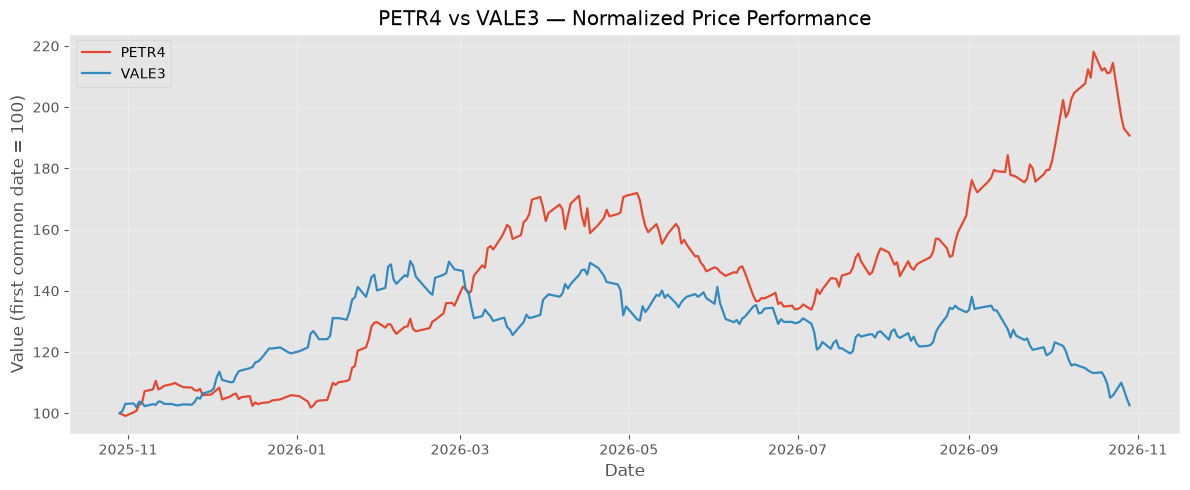

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))

for ticker in prices.columns:
    ax.plot(
        normalized_prices.index,
        normalized_prices[ticker],
        label=ticker,
        linewidth=1.6
    )

ax.set_title("PETR4 vs VALE3 — Normalized Price Performance")
ax.set_xlabel("Date")
ax.set_ylabel("Value (first common date = 100)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "stock-performance.png", dpi=150, bbox_inches="tight")
plt.show()


# 6. Comparative chart: Cumulative returns

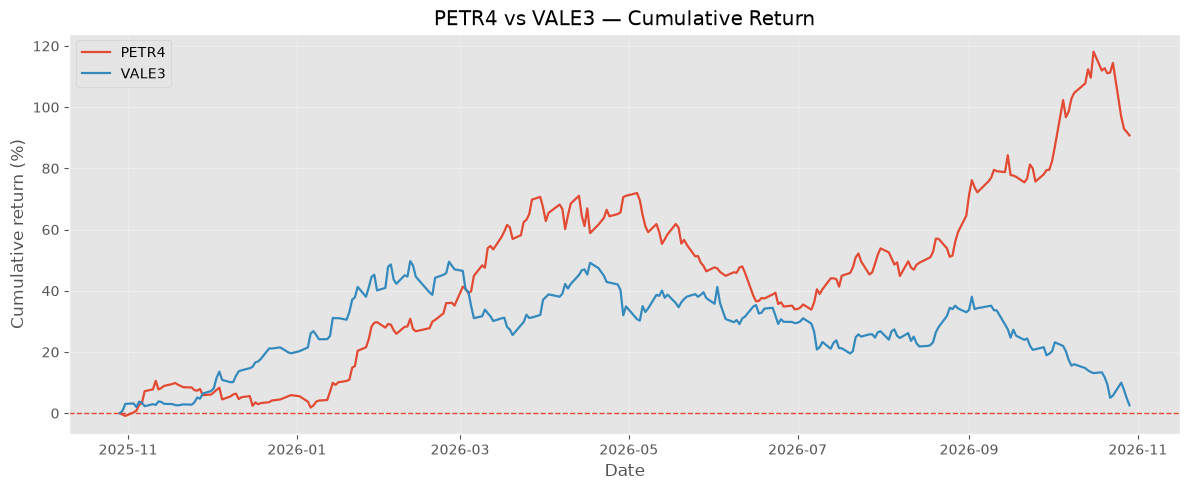

In [15]:
fig, ax = plt.subplots(figsize=(12, 5))

for ticker in prices.columns:
    ax.plot(
        cumulative_returns.index,
        cumulative_returns[ticker] * 100,
        label=ticker,
        linewidth=1.6
    )

ax.axhline(0, linewidth=1, linestyle="--")
ax.set_title("PETR4 vs VALE3 — Cumulative Return")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative return (%)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "returns-comparison.png", dpi=150, bbox_inches="tight")
plt.show()


# 7. Individual charts for each asset

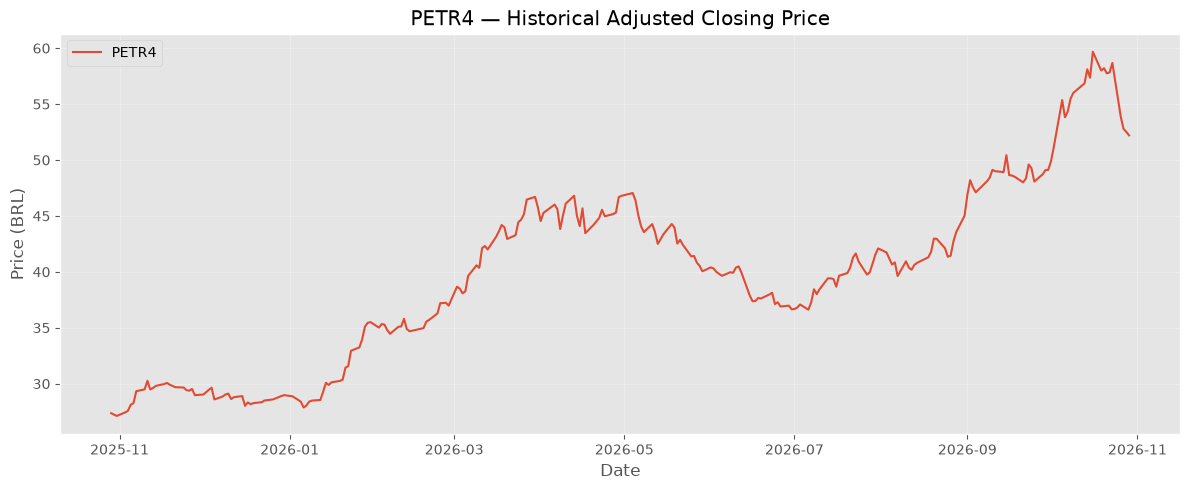

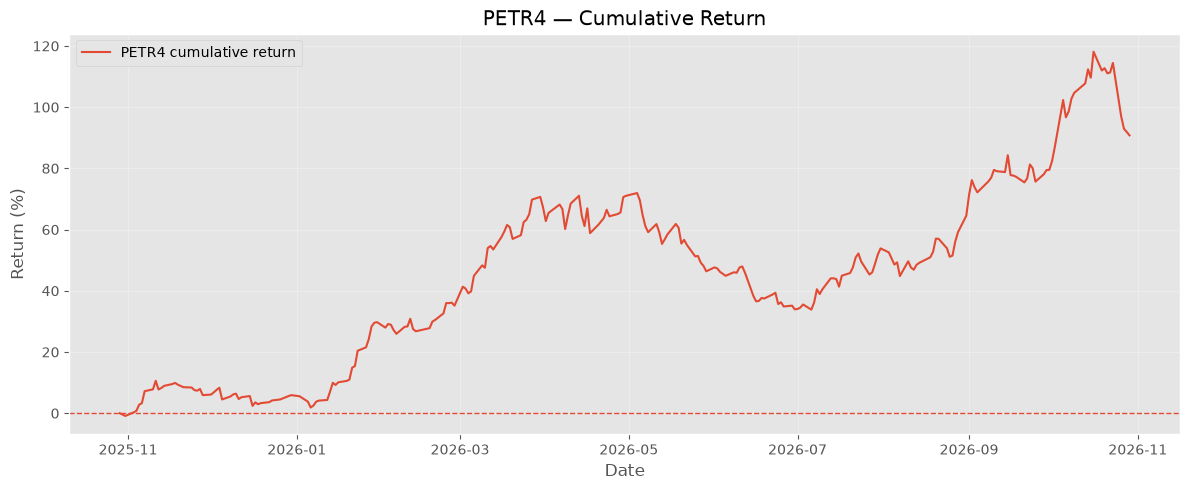

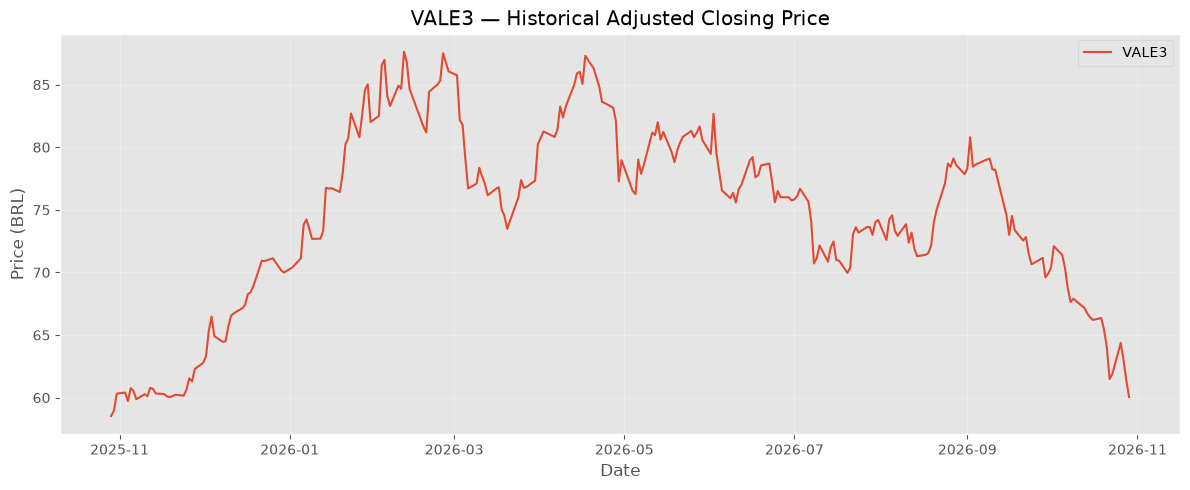

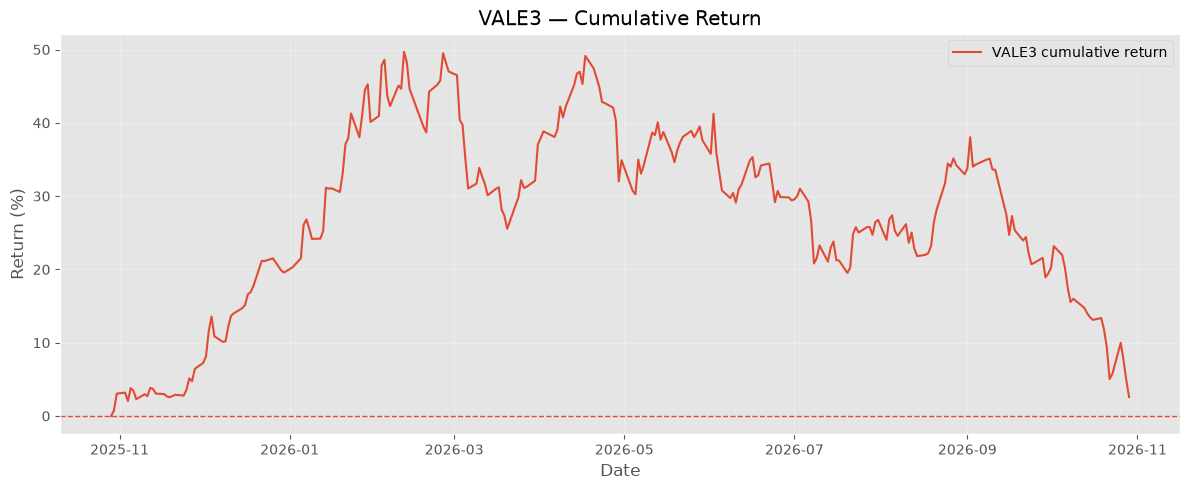

In [16]:
for ticker in prices.columns:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(prices.index, prices[ticker], label=ticker, linewidth=1.5)
    ax.set_title(f"{ticker} — Historical Adjusted Closing Price")
    ax.set_xlabel("Date")
    ax.set_ylabel("Price (BRL)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(
        IMAGES_DIR / f"{ticker.lower()}-stock-performance.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(
        cumulative_returns.index,
        cumulative_returns[ticker] * 100,
        label=f"{ticker} cumulative return",
        linewidth=1.5
    )
    ax.axhline(0, linewidth=1, linestyle="--")
    ax.set_title(f"{ticker} — Cumulative Return")
    ax.set_xlabel("Date")
    ax.set_ylabel("Return (%)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(
        IMAGES_DIR / f"{ticker.lower()}-returns-comparison.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()


# 8. Daily return chart

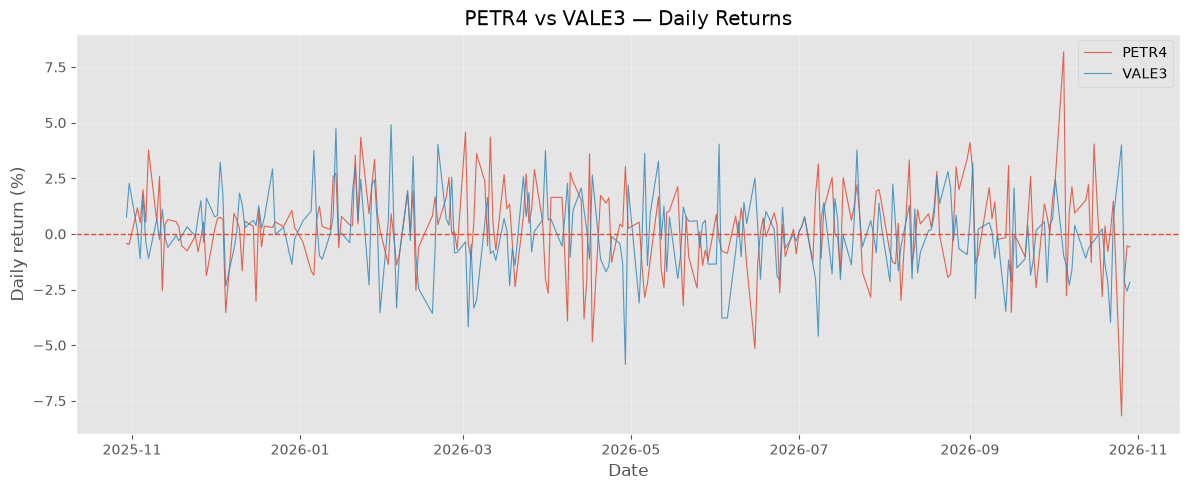

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))

for ticker in daily_returns.columns:
    ax.plot(
        daily_returns.index,
        daily_returns[ticker] * 100,
        linewidth=0.8,
        label=ticker,
        alpha=0.85
    )

ax.axhline(0, linewidth=1, linestyle="--")
ax.set_title("PETR4 vs VALE3 — Daily Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Daily return (%)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "daily-returns-comparison.png", dpi=150, bbox_inches="tight")
plt.show()


# 9. Summary indicators

In [18]:
summary = pd.DataFrame({
    "First Adjusted Close (BRL)": prices.iloc[0],
    "Latest Adjusted Close (BRL)": prices.iloc[-1],
    "Cumulative Return (%)": cumulative_returns.iloc[-1] * 100,
    "Average Daily Return (%)": daily_returns.mean() * 100,
    "Daily Volatility (%)": daily_returns.std() * 100,
    "Positive Days (%)": (daily_returns > 0).mean() * 100,
})

display(summary.round(3))

print("Charts saved to:", IMAGES_DIR)


,First Adjusted Close (BRL),Latest Adjusted Close (BRL),Cumulative Return (%),Average Daily Return (%),Daily Volatility (%),Positive Days (%)
PETR4,27.363,52.20,90.772,0.279,1.889,60.643
VALE3,58.537,60.05,2.585,0.026,1.750,52.610


Charts saved to: c:\Users\Rafael\Documents\Projects\Personal\Data\b3-analytics\docs\images
